In [ ]:
# FireWatch AI: Fire and Smoke Model Training

In this notebook, I am training the fire and smoke detection model for my FireWatch AI project using YOLO.

My goal is to build a model that can identify fire and smoke in images and later support detection in prerecorded videos. This model will become one of the core components of my larger safety-monitoring pipeline.

I have prepared a separate candidate dataset with bounding-box annotations and verified its train, validation, and test splits. I will use this prepared dataset while preserving the original dataset.

Before training, I will verify that Google Drive is connected and the project files are accessible. I will then configure reproducible training, evaluate the trained model, and save the model artifacts for later integration into FireWatch AI.


## Step 1: Verify the Project Environment

Before I install packages or start training, I need to confirm that the current Colab session can access the correct project directory and prepared fire/smoke dataset.

This avoids training against an incorrect path or accidentally using the original dataset instead of the prepared candidate dataset. This step only checks the environment and does not modify any dataset files.

In [ ]:
from pathlib import Path
from google.colab import drive

# I connect to the standard Drive mount without forcing a remount.
drive.mount("/content/drive", force_remount=False)

PROJECT_ROOT = Path("/content/drive/MyDrive/FireWatch-AI")
DATASET_DIR = PROJECT_ROOT / "datasets/candidates/fire_smoke_v2_bbox_candidate"
DATA_YAML = DATASET_DIR / "data.yaml"

print("Project exists:", PROJECT_ROOT.is_dir(), PROJECT_ROOT)
print("Dataset exists:", DATASET_DIR.is_dir(), DATASET_DIR)
print("Dataset YAML exists:", DATA_YAML.is_file(), DATA_YAML)

if not PROJECT_ROOT.is_dir() or not DATASET_DIR.is_dir() or not DATA_YAML.is_file():
    raise FileNotFoundError(
        "Required FireWatch AI project or dataset path is unavailable. "
        "Stop here and verify the Drive path before training."
    )

print("\nEnvironment path check: PASS")

Mounted at /content/drive
Project exists: True /content/drive/MyDrive/FireWatch-AI
Dataset exists: True /content/drive/MyDrive/FireWatch-AI/datasets/candidates/fire_smoke_v2_bbox_candidate
Dataset YAML exists: True /content/drive/MyDrive/FireWatch-AI/datasets/candidates/fire_smoke_v2_bbox_candidate/data.yaml

Environment path check: PASS


## Step 2: Verify Dataset Configuration and Classes

Before training, I will inspect the prepared dataset configuration. My fire/smoke model must learn exactly two classes: `fire` and `smoke`.

I will confirm the class names, number of classes, and train, validation, and test paths. This helps prevent class-mapping errors and ensures that the model uses the prepared candidate dataset rather than the original annotations.

This step only reads the configuration. It does not start training or modify the dataset.

In [ ]:
import yaml

# I load the configuration from the verified candidate dataset.
with DATA_YAML.open("r", encoding="utf-8") as file:
    data_config = yaml.safe_load(file)

print("Classes:", data_config.get("names"))
print("Number of classes:", data_config.get("nc"))

for split in ("train", "val", "test"):
    split_path = DATASET_DIR / data_config[split]
    print(f"{split} path exists:", split_path.is_dir(), split_path)

# I stop if the configuration does not match my project requirements.
assert data_config.get("names") == ["fire", "smoke"], "Unexpected class names"
assert data_config.get("nc") == 2, "Expected exactly 2 classes"

for split in ("train", "val", "test"):
    assert (DATASET_DIR / data_config[split]).is_dir(), (
        f"Missing image directory for {split}: {data_config[split]}"
    )

print("\nDataset configuration check: PASS")

Classes: ['fire', 'smoke']
Number of classes: 2
train path exists: True /content/drive/MyDrive/FireWatch-AI/datasets/candidates/fire_smoke_v2_bbox_candidate/train/images
val path exists: True /content/drive/MyDrive/FireWatch-AI/datasets/candidates/fire_smoke_v2_bbox_candidate/valid/images
test path exists: True /content/drive/MyDrive/FireWatch-AI/datasets/candidates/fire_smoke_v2_bbox_candidate/test/images

Dataset configuration check: PASS


In [ ]:
## Step 3: Check Training Hardware and Software

I will check whether Google Colab has provided a GPU and identify the installed Ultralytics version.

YOLO training can be significantly slower on a CPU, so I want to confirm the available hardware before starting. I will also avoid reinstalling packages if the required library is already available.

This step only checks the environment. It does not download model weights or begin training.

In [5]:
%pip install -q ultralytics

In [ ]:
import sys
import torch
import ultralytics
from ultralytics import YOLO

# I record the environment so I can reproduce the training setup.
print("Python version:", sys.version.split()[0])
print("PyTorch version:", torch.__version__)
print("Ultralytics version:", ultralytics.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("GPU not detected. In Colab, check Runtime > Change runtime type > T4 GPU.")

print("\nTraining environment check complete.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Python version: 3.13.16
PyTorch version: 2.11.0+cu130
Ultralytics version: 8.4.190
CUDA available: True
GPU: Tesla T4
CUDA version: 13.0

Training environment check complete.


In [ ]:
## Step 4: Load the YOLO Model

I will start with the lightweight `yolo26n.pt` checkpoint. The `n` version is designed to be small and efficient, making it a practical starting point for training on a Colab T4 GPU.

This step loads the pretrained model into memory. It does not train the model or change the original dataset. Training will be configured separately so we can save the results and evaluate the model properly.

In [6]:
from ultralytics import YOLO

MODEL_NAME = "yolo26n.pt"

model = YOLO(MODEL_NAME)

print("Model loaded successfully.")
print("Checkpoint:", MODEL_NAME)
print("Number of model classes before fine-tuning:", len(model.names))
print("GPU available for training:", __import__("torch").cuda.is_available())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Model loaded successfully.
Checkpoint: yolo26n.pt
Number of model classes before fine-tuning: 80
GPU available for training: True


In [ ]:
## Step 5: Configure Training

I have loaded the pretrained YOLO26n checkpoint. Its original 80 classes come from pretraining, so the model will be adapted to our dataset's two target classes: `fire` and `smoke`.

I will save training outputs separately from the dataset and use the validation split during training. The test split will remain untouched until final evaluation. This run will start with 50 epochs and 640-pixel images, using a fixed seed to help make the experiment reproducible.

In [ ]:
from pathlib import Path
import torch

# Store training artifacts separately from the prepared dataset.
RUNS_DIR = PROJECT_ROOT / "runs" / "fire_smoke"
RUNS_DIR.mkdir(parents=True, exist_ok=True)

# Fixed settings for the first training experiment.
TRAINING_CONFIG = {
    "data": str(DATA_YAML),
    "epochs": 50,
    "imgsz": 640,
    "batch": 16,
    "device": 0 if torch.cuda.is_available() else "cpu",
    "seed": 42,
    "deterministic": True,
    "workers": 2,
    "project": str(RUNS_DIR),
    "name": "yolo26n_fire_smoke_v1",
    "exist_ok": True,
    "plots": True,
    "save": True,
    "verbose": True,
}

print("Training configuration:")
for key, value in TRAINING_CONFIG.items():
    print(f"{key}: {value}")

print("\nOutput directory:", RUNS_DIR)
print("Output directory exists:", RUNS_DIR.is_dir())
print("Original dataset kept separate:", DATASET_DIR != RUNS_DIR)

Training configuration:
data: /content/drive/MyDrive/FireWatch-AI/datasets/candidates/fire_smoke_v2_bbox_candidate/data.yaml
epochs: 50
imgsz: 640
batch: 16
device: 0
seed: 42
deterministic: True
workers: 2
project: /content/drive/MyDrive/FireWatch-AI/runs/fire_smoke
name: yolo26n_fire_smoke_v1
exist_ok: True
plots: True
save: True
verbose: True

Output directory: /content/drive/MyDrive/FireWatch-AI/runs/fire_smoke
Output directory exists: True
Original dataset kept separate: True


In [ ]:
## Step 6: Train the Fire and Smoke Detector

I will fine-tune the pretrained YOLO26n model on our prepared fire and smoke dataset. Training will use the training split, while the validation split will help assess model performance after each epoch.

The model's checkpoints, training metrics, and plots will be saved in the dedicated run directory, separate from the dataset. I will use the best checkpoint for the next evaluation step and reserve the test split for final evaluation.

In [ ]:
# Start training using the configuration verified in Step 5.
results = model.train(**TRAINING_CONFIG)

print("\nTraining call completed.")
print("Best checkpoint:", RUNS_DIR / "yolo26n_fire_smoke_v1" / "weights" / "best.pt")
print("Last checkpoint:", RUNS_DIR / "yolo26n_fire_smoke_v1" / "weights" / "last.pt")
print("Training results directory:", RUNS_DIR / "yolo26n_fire_smoke_v1")

Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/FireWatch-AI/datasets/candidates/fire_smoke_v2_bbox_candidate/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, 

In [1]:
from pathlib import Path
from google.colab import drive

# I connect to the standard Drive mount without forcing a remount.
drive.mount("/content/drive", force_remount=False)

PROJECT_ROOT = Path("/content/drive/MyDrive/FireWatch-AI")
DATASET_DIR = PROJECT_ROOT / "datasets/candidates/fire_smoke_v2_bbox_candidate"
DATA_YAML = DATASET_DIR / "data.yaml"

print("Project exists:", PROJECT_ROOT.is_dir(), PROJECT_ROOT)
print("Dataset exists:", DATASET_DIR.is_dir(), DATASET_DIR)
print("Dataset YAML exists:", DATA_YAML.is_file(), DATA_YAML)

if not PROJECT_ROOT.is_dir() or not DATASET_DIR.is_dir() or not DATA_YAML.is_file():
    raise FileNotFoundError(
        "Required FireWatch AI project or dataset path is unavailable. "
        "Stop here and verify the Drive path before training."
    )

print("\nEnvironment path check: PASS")

Mounted at /content/drive
Project exists: True /content/drive/MyDrive/FireWatch-AI
Dataset exists: True /content/drive/MyDrive/FireWatch-AI/datasets/candidates/fire_smoke_v2_bbox_candidate
Dataset YAML exists: True /content/drive/MyDrive/FireWatch-AI/datasets/candidates/fire_smoke_v2_bbox_candidate/data.yaml

Environment path check: PASS


In [2]:
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/FireWatch-AI")
DATASET_DIR = PROJECT_ROOT / "datasets/candidates/fire_smoke_v2_bbox_candidate"
DATA_YAML = DATASET_DIR / "data.yaml"

RUNS_DIR = PROJECT_ROOT / "runs" / "fire_smoke"

BEST_MODEL_PATH = (
    RUNS_DIR
    / "yolo26n_fire_smoke_v1"
    / "weights"
    / "best.pt"
)

print("Dataset YAML exists:", DATA_YAML.is_file())
print("Best checkpoint exists:", BEST_MODEL_PATH.is_file())
print("Test images directory exists:", (DATASET_DIR / "test/images").is_dir())

assert DATA_YAML.is_file(), "Dataset YAML not found."
assert BEST_MODEL_PATH.is_file(), "Best checkpoint not found."
assert (DATASET_DIR / "test/images").is_dir(), "Test images directory not found."

print("Checkpoint verification: PASS")

Dataset YAML exists: True
Best checkpoint exists: True
Test images directory exists: True
Checkpoint verification: PASS


In [7]:
from ultralytics import YOLO

best_model = YOLO(str(BEST_MODEL_PATH))

test_results = best_model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True,
    project=str(RUNS_DIR),
    name="yolo26n_fire_smoke_test_v1",
    exist_ok=True,
)

print("\nHeld-out test evaluation completed.")
print("Precision:", round(test_results.box.mp, 4))
print("Recall:", round(test_results.box.mr, 4))
print("mAP@50:", round(test_results.box.map50, 4))
print("mAP@50:95:", round(test_results.box.map, 4))

Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.9±0.6 ms, read: 0.1±0.0 MB/s, size: 44.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/FireWatch-AI/datasets/candidates/fire_smoke_v2_bbox_candidate/test/labels... 300 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 300/300 3.2it/s 1:35
val: New cache created: /content/drive/MyDrive/FireWatch-AI/datasets/candidates/fire_smoke_v2_bbox_candidate/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 4.1it/s 4.7s
                   all        300        480      0.907      0.827      0.871      0.597
                  fire        219        361      0.868       0.8

In [ ]:
## Step 7: Inspect Training Plots

I have completed training and evaluated the fire/smoke detector on the held-out test split. Before moving to practical inference, I will inspect the saved training plots to understand how the losses and detection metrics changed across epochs.

This helps identify training instability or possible overfitting. I will inspect the existing outputs without retraining the model.


--- results.png ---


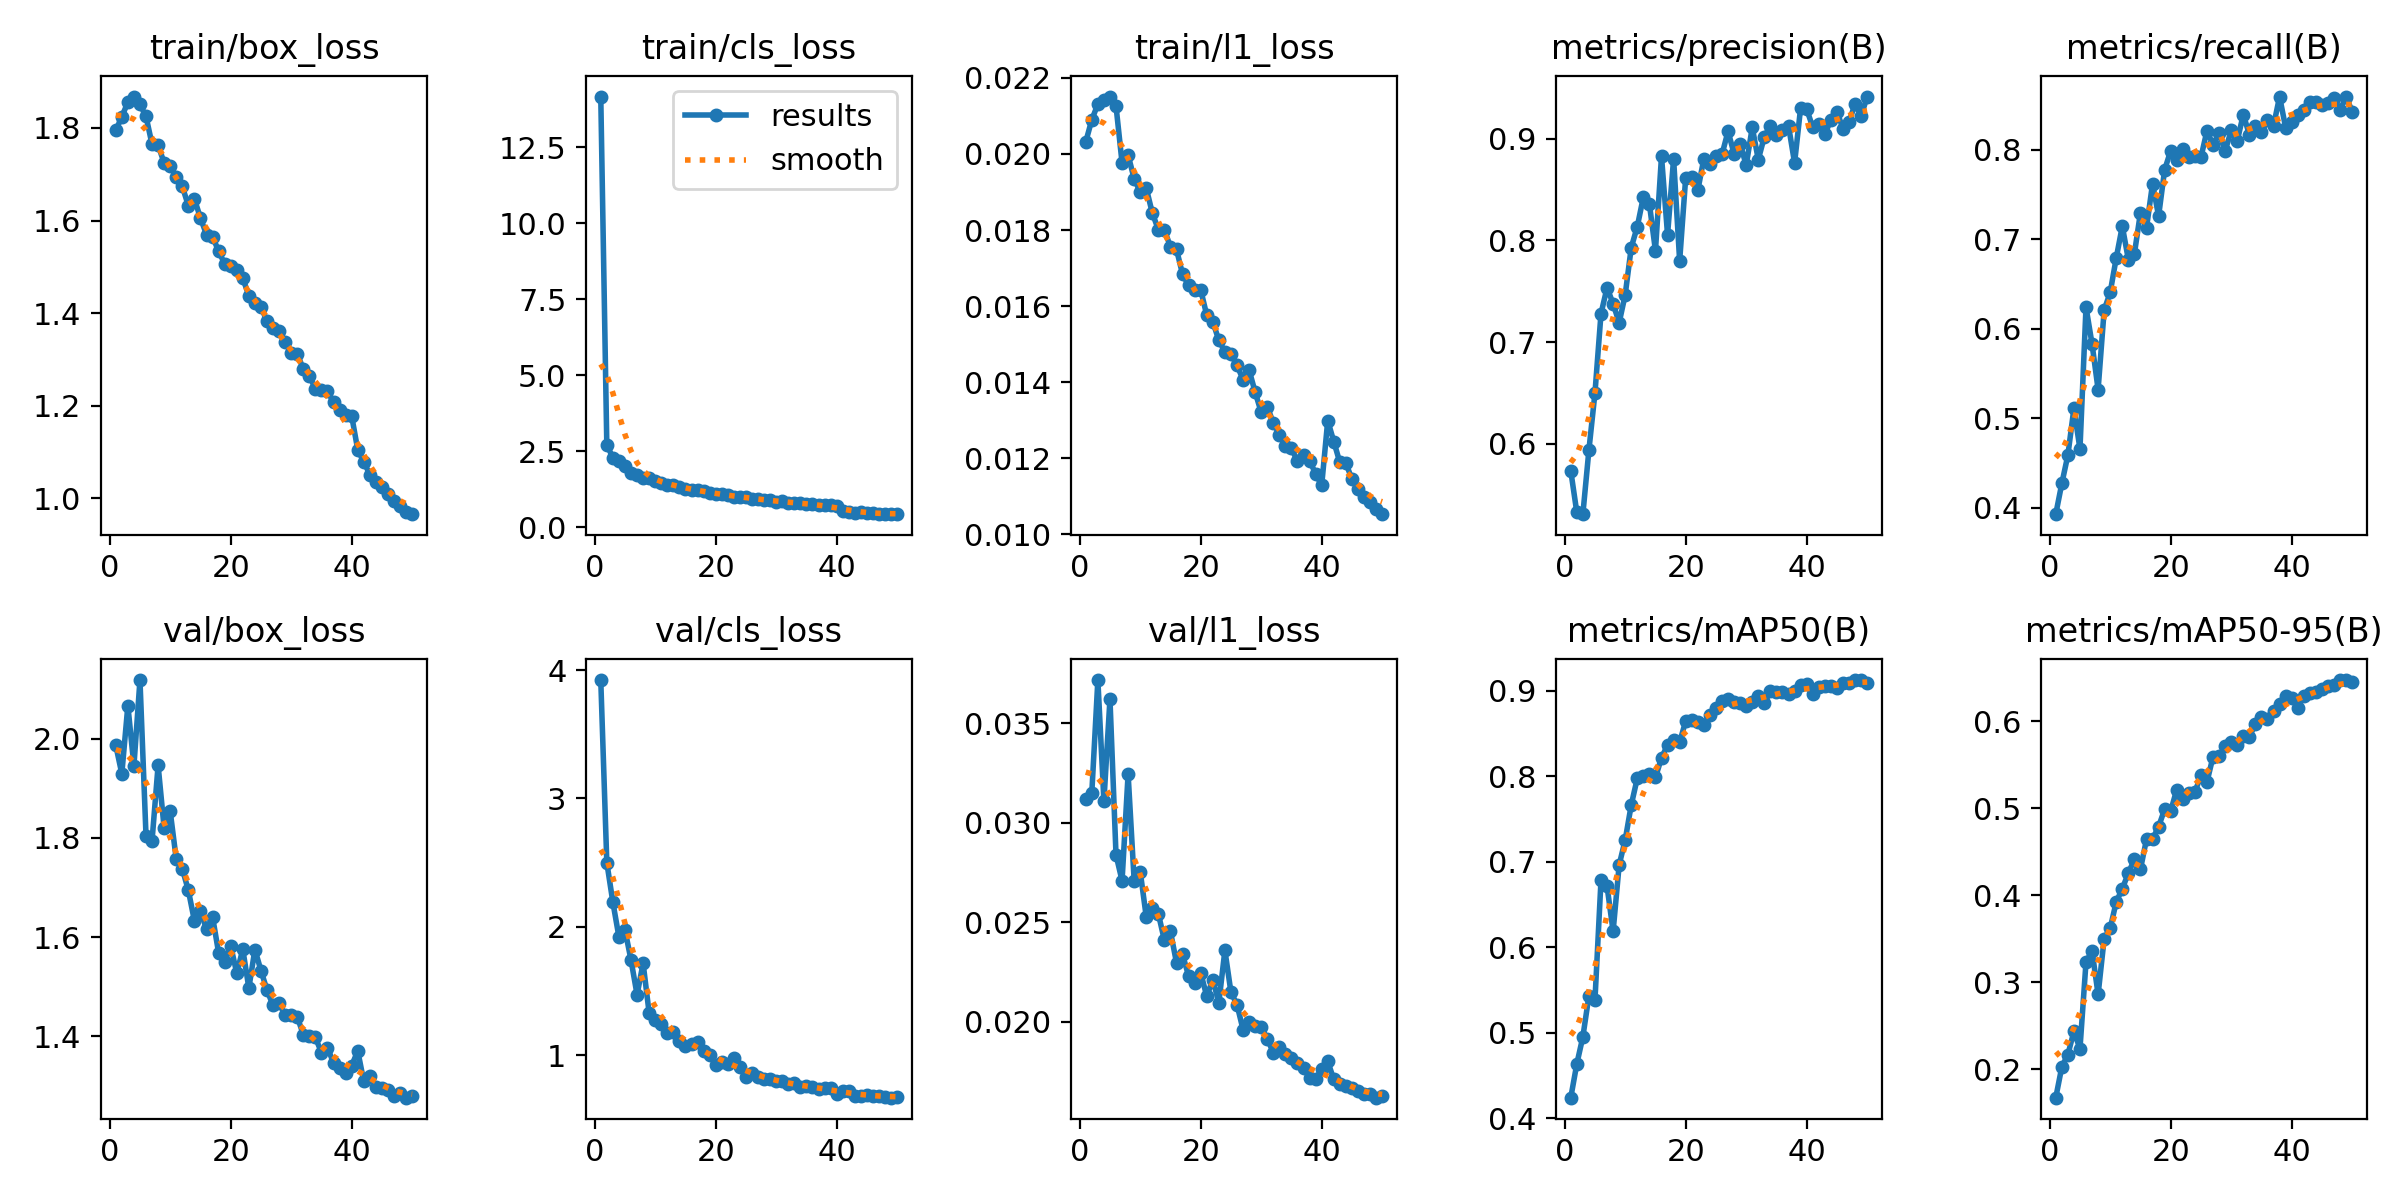


--- confusion_matrix.png ---


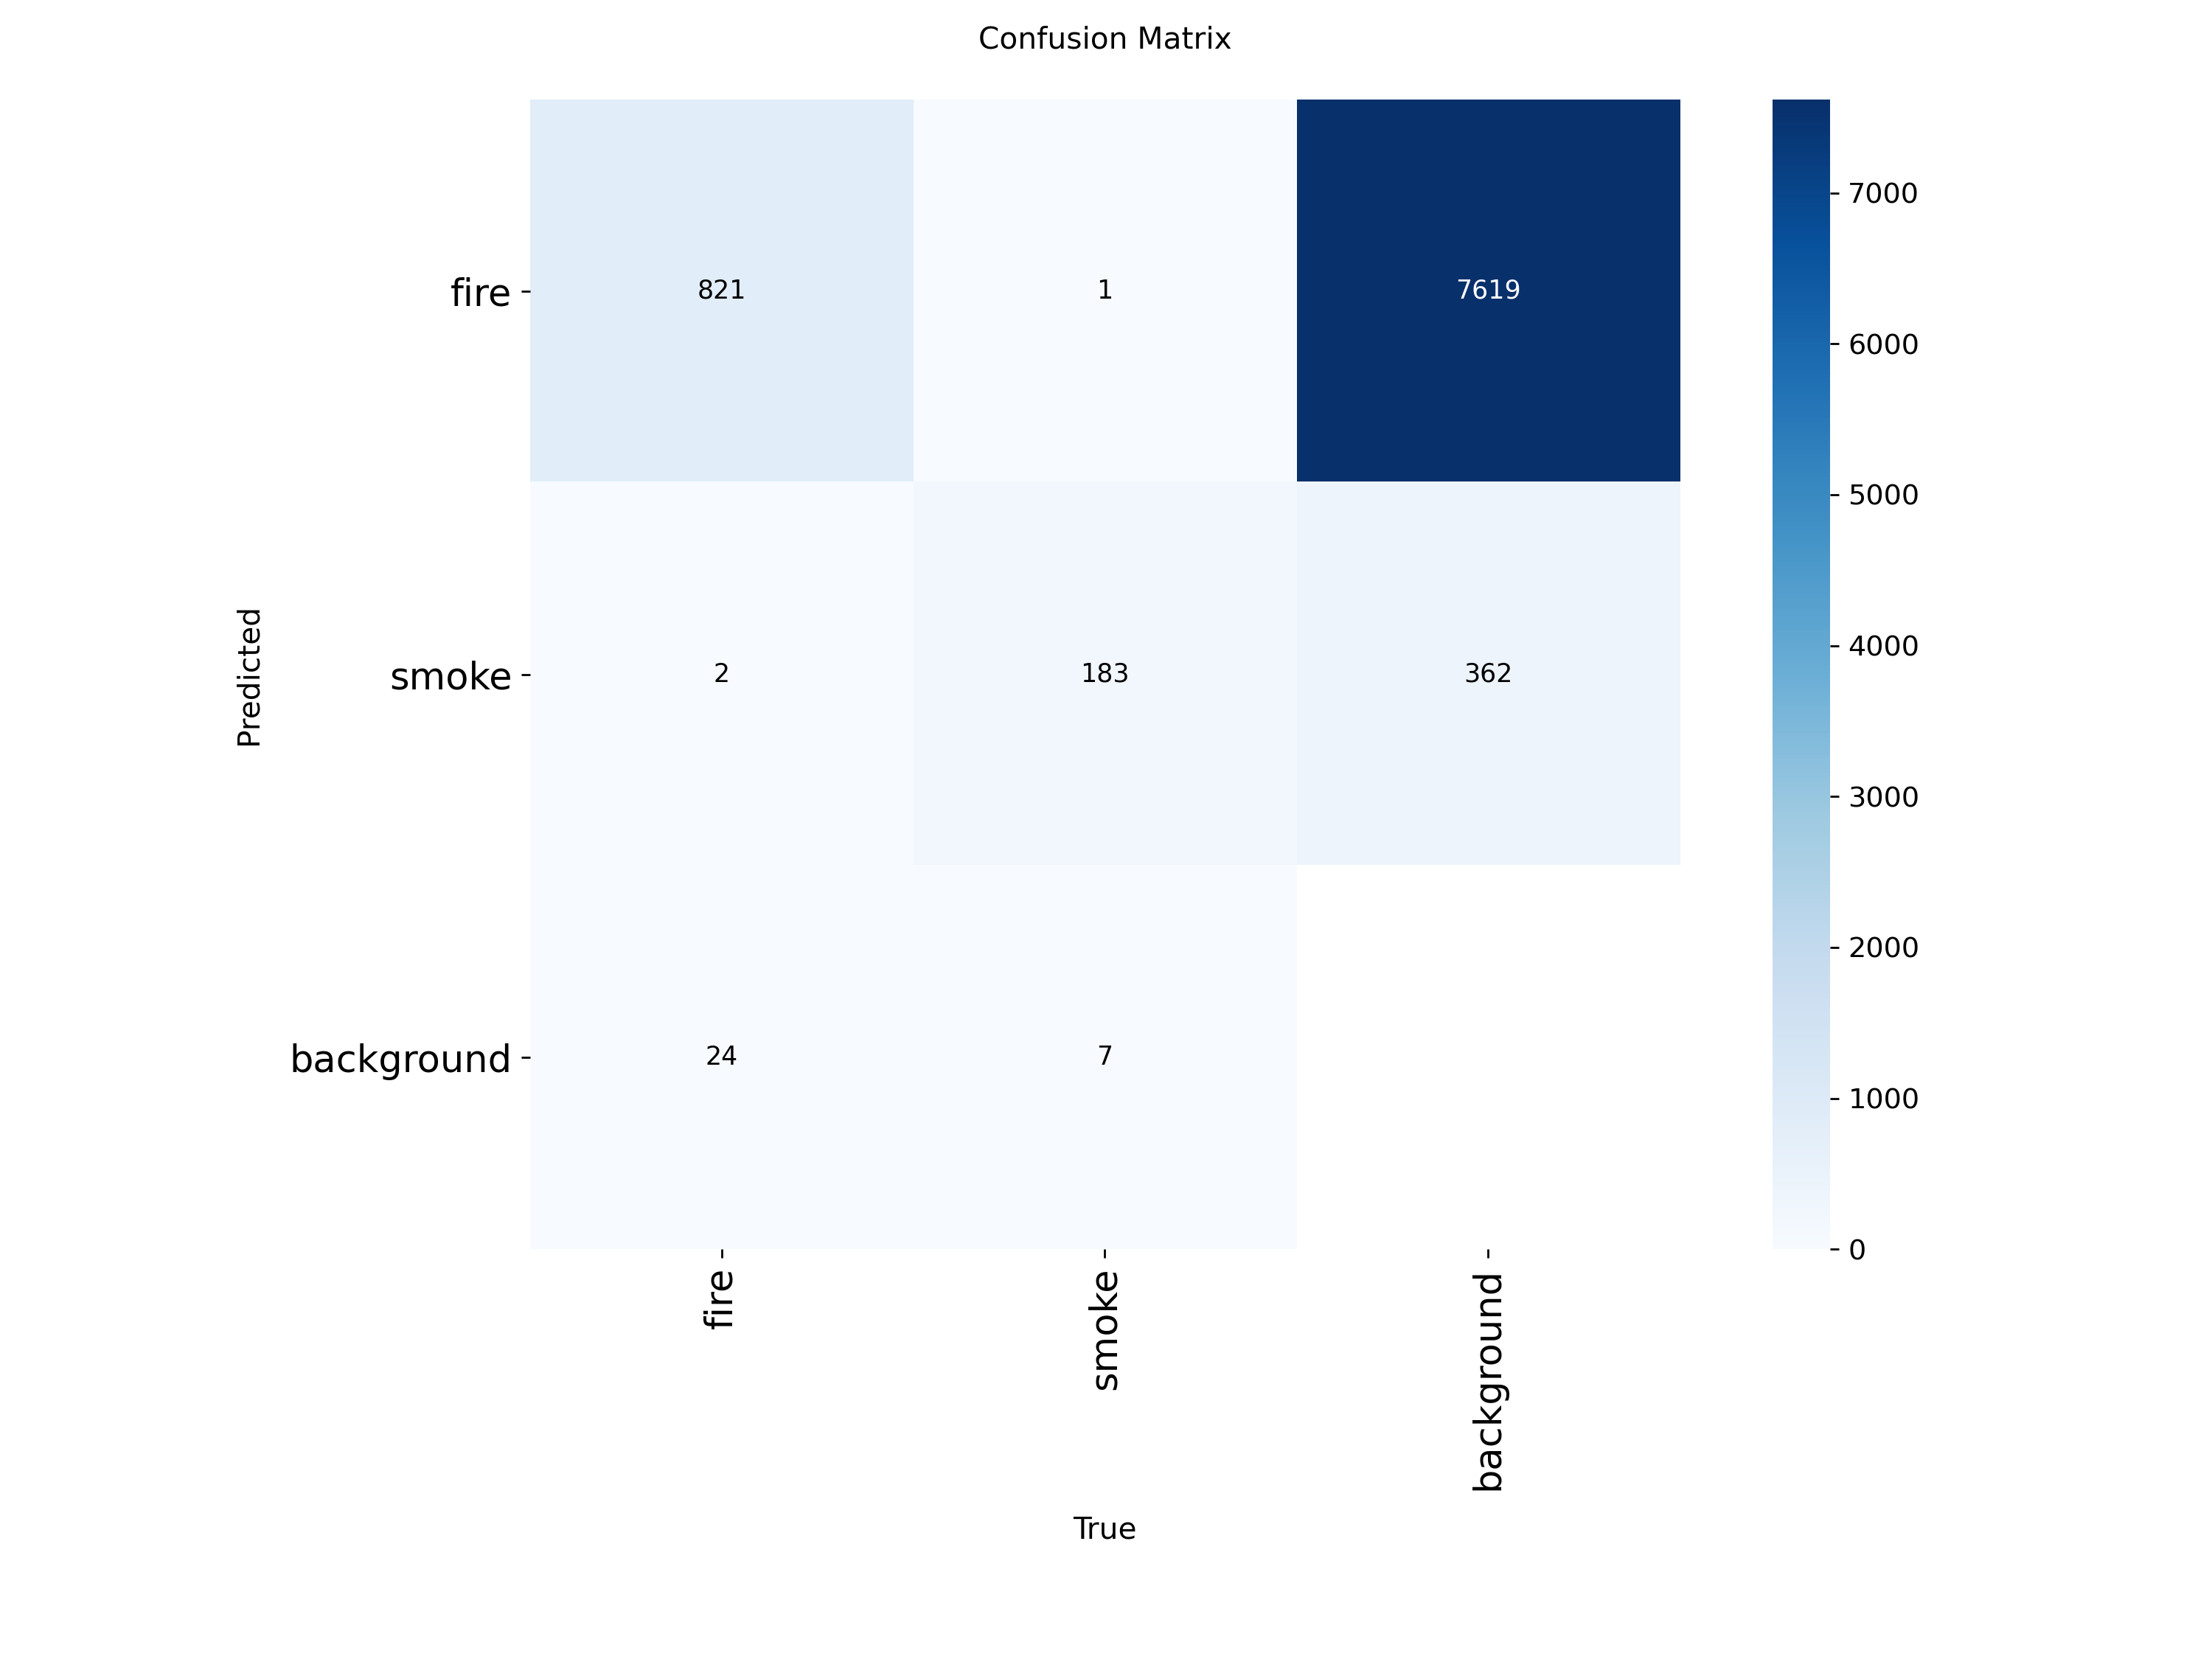


--- confusion_matrix_normalized.png ---


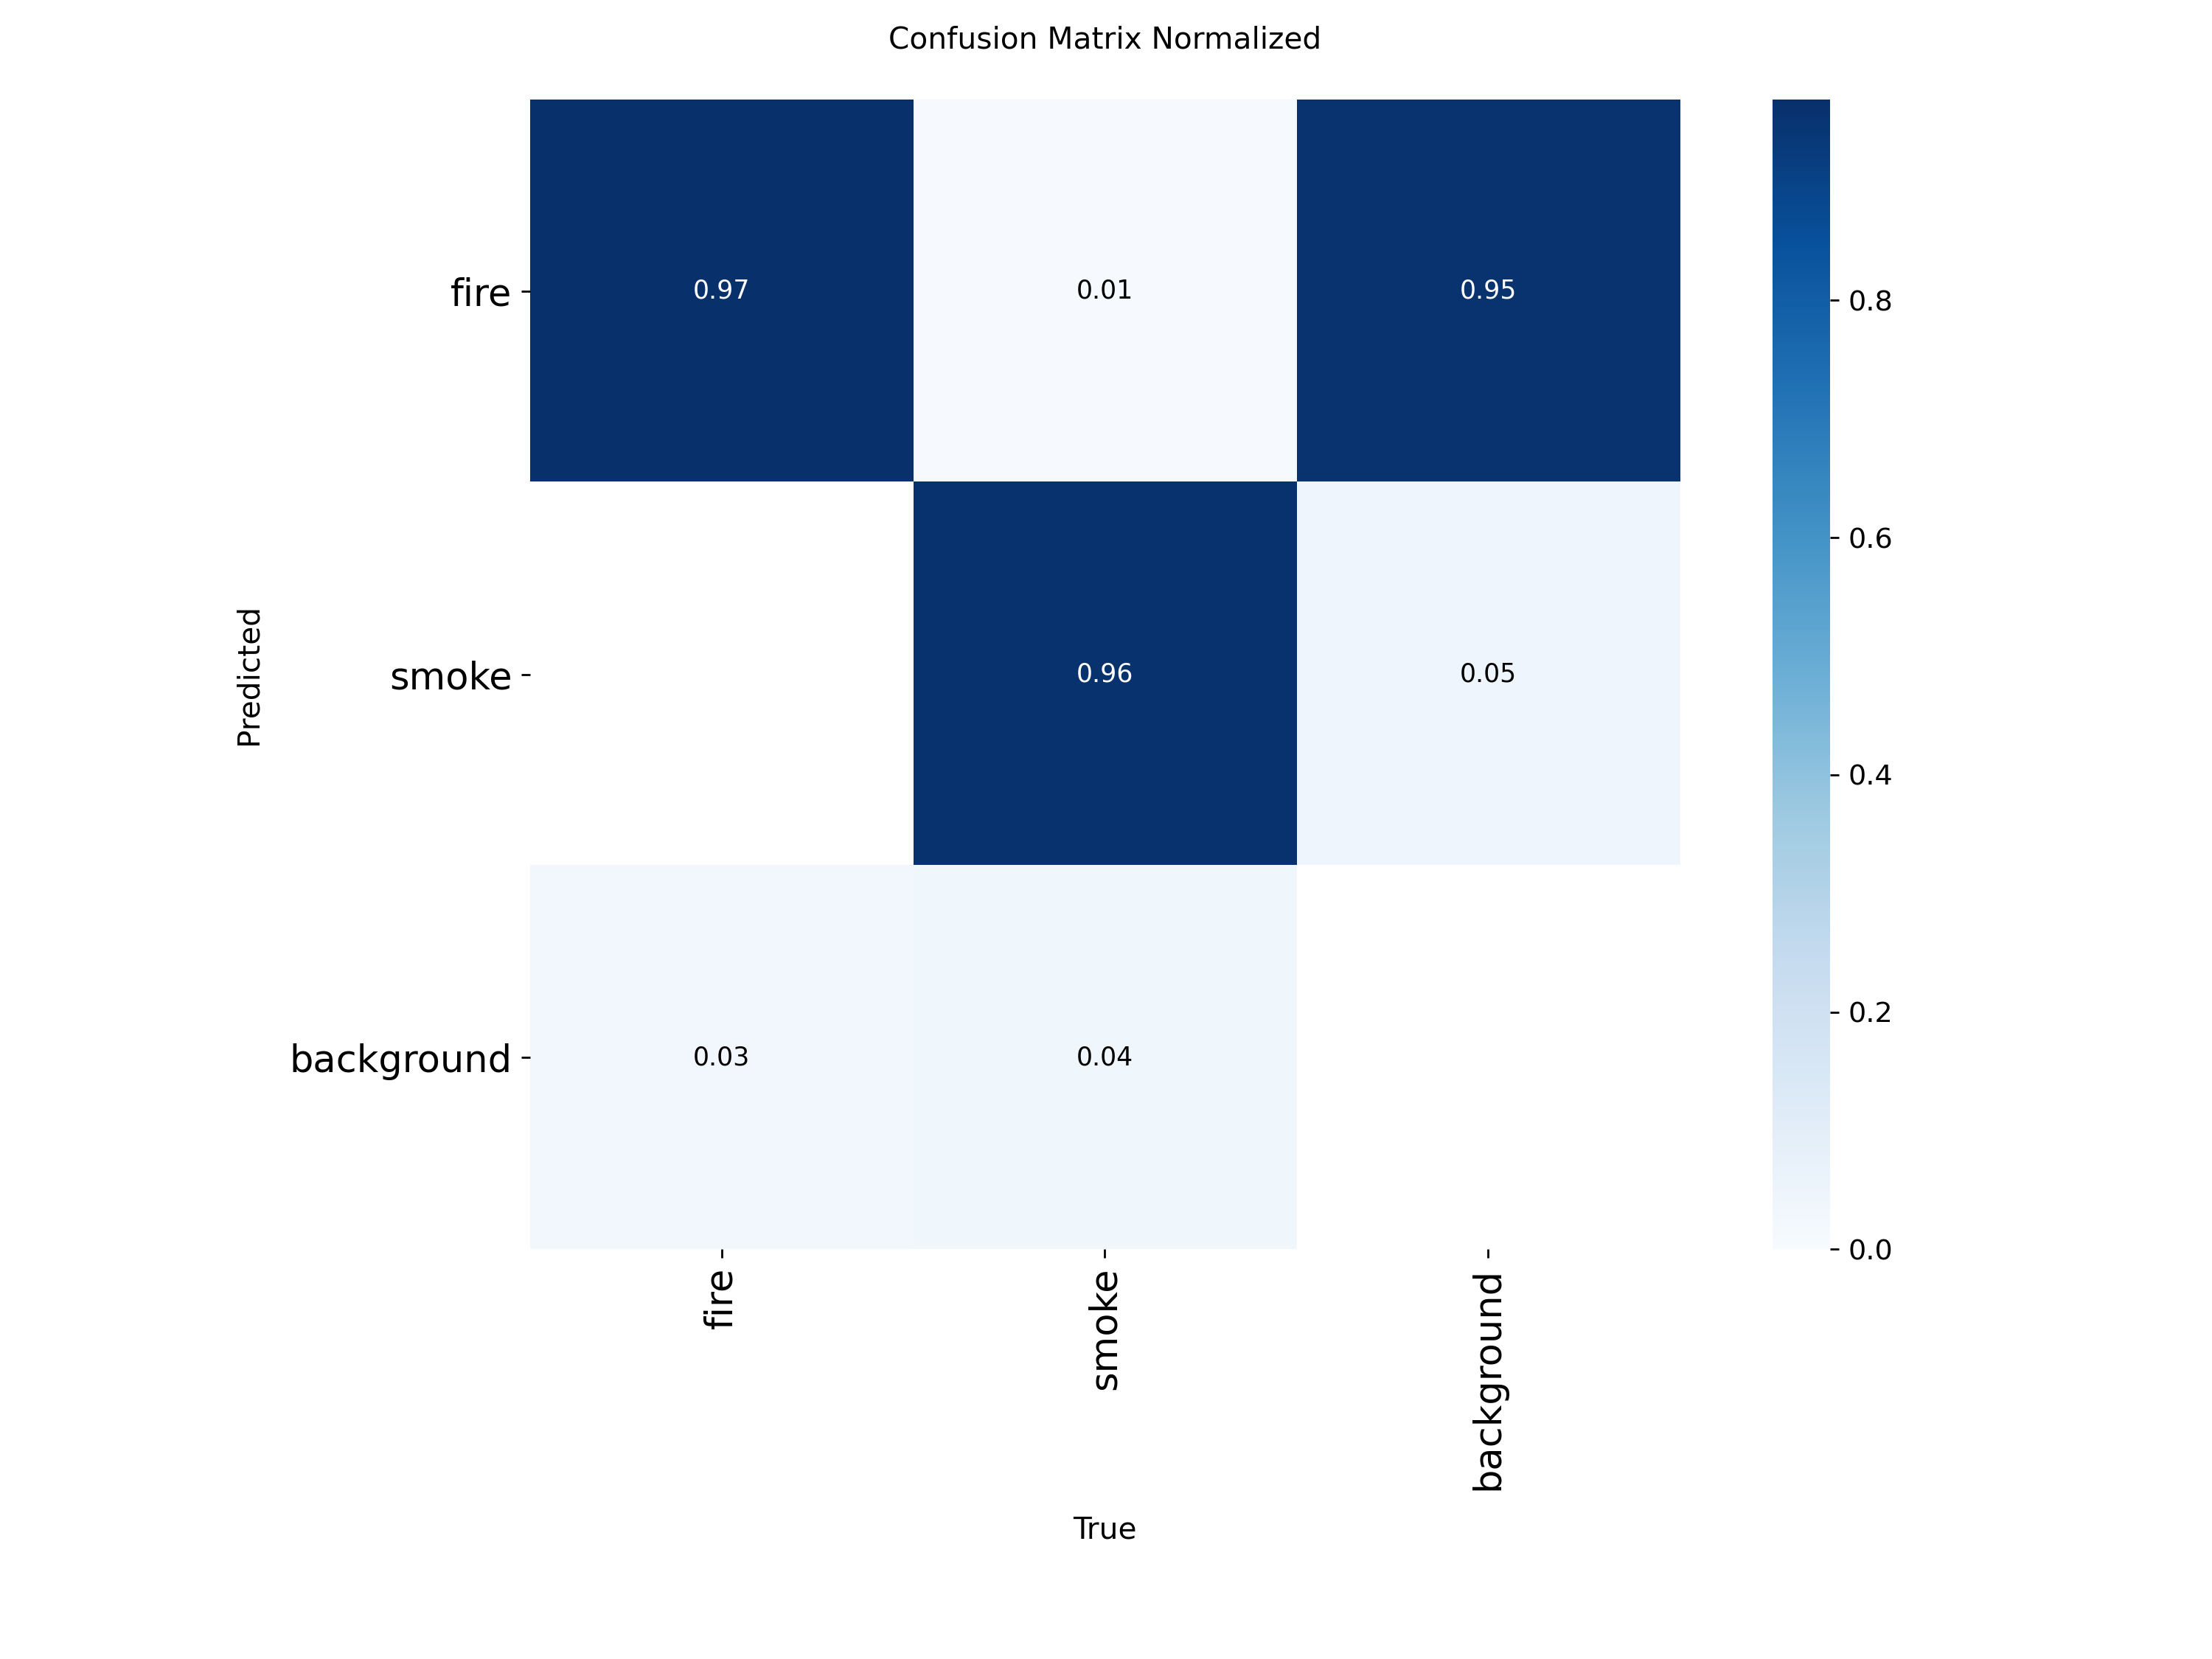

Not found: PR_curve.png
Not found: F1_curve.png
Not found: P_curve.png
Not found: R_curve.png

--- labels.jpg ---


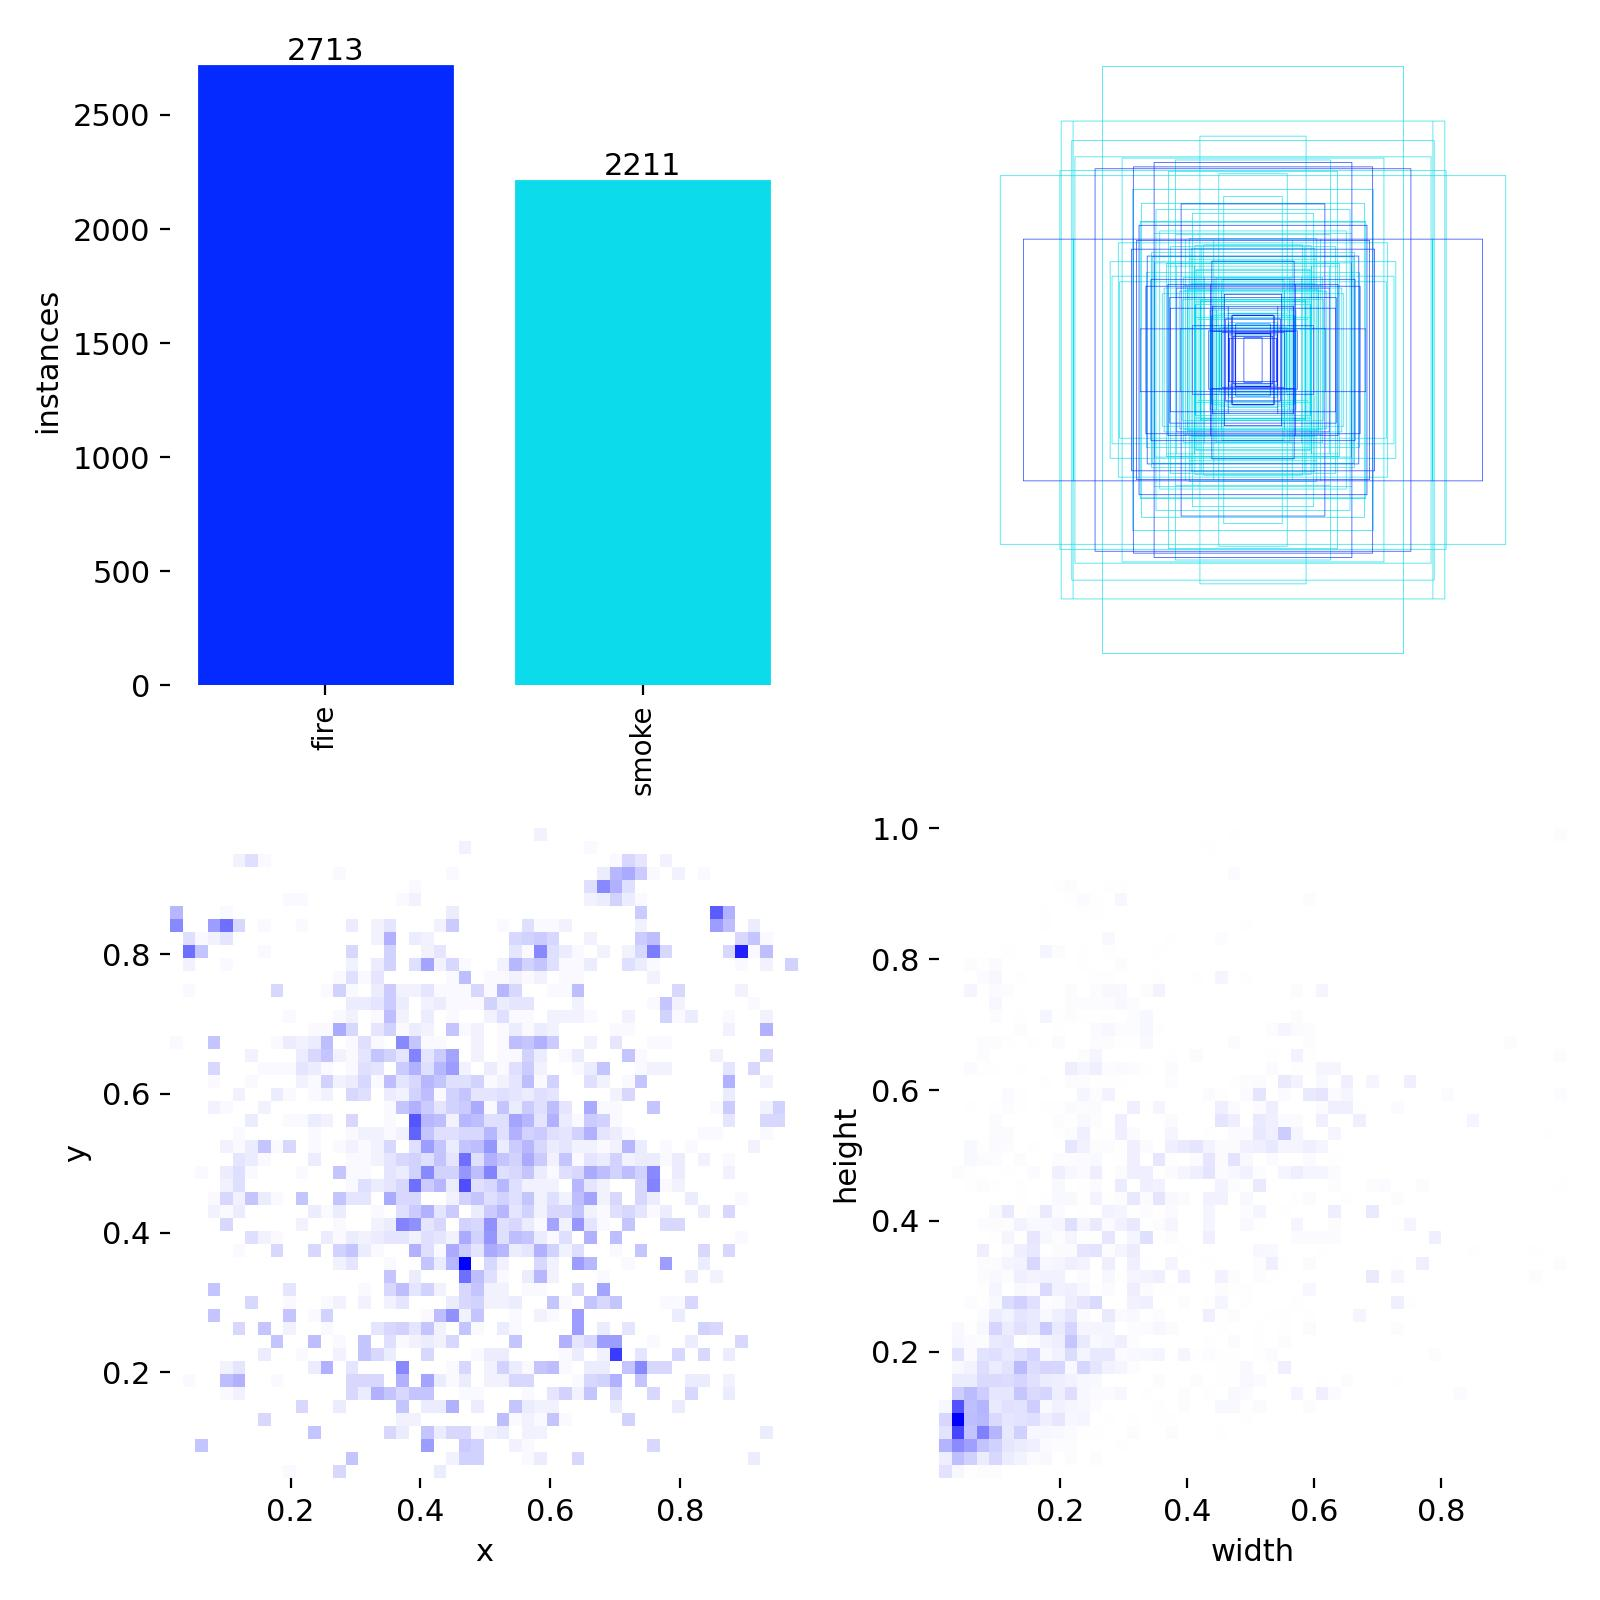

In [8]:
from pathlib import Path
from IPython.display import display, Image

RUN_DIR = (
    PROJECT_ROOT
    / "runs/fire_smoke/yolo26n_fire_smoke_v1"
)

plot_files = [
    "results.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "PR_curve.png",
    "F1_curve.png",
    "P_curve.png",
    "R_curve.png",
    "labels.jpg",
]

for filename in plot_files:
    plot_path = RUN_DIR / filename

    if plot_path.is_file():
        print(f"\n--- {filename} ---")
        display(Image(filename=str(plot_path)))
    else:
        print(f"Not found: {filename}")

In [9]:
from pathlib import Path
import shutil

RUN_DIR = (
    PROJECT_ROOT
    / "runs/fire_smoke/yolo26n_fire_smoke_v1"
)

DOCS_IMAGES_DIR = PROJECT_ROOT / "docs" / "images"
DOCS_IMAGES_DIR.mkdir(parents=True, exist_ok=True)

plot_mapping = {
    "results.png": "fire_smoke_results.png",
    "confusion_matrix.png": "fire_smoke_confusion_matrix.png",
    "confusion_matrix_normalized.png": "fire_smoke_confusion_matrix_normalized.png",
    "labels.jpg": "fire_smoke_labels.jpg",
}

for source_name, destination_name in plot_mapping.items():
    source = RUN_DIR / source_name
    destination = DOCS_IMAGES_DIR / destination_name

    if source.is_file():
        shutil.copy2(source, destination)
        print(f"Copied: {destination_name}")
    else:
        print(f"Not found: {source_name}")

print("\nREADME image folder:", DOCS_IMAGES_DIR)
print("Saved files:", sorted(p.name for p in DOCS_IMAGES_DIR.iterdir()))

Copied: fire_smoke_results.png
Copied: fire_smoke_confusion_matrix.png
Copied: fire_smoke_confusion_matrix_normalized.png
Copied: fire_smoke_labels.jpg

README image folder: /content/drive/MyDrive/FireWatch-AI/docs/images
Saved files: ['fire_smoke_confusion_matrix.png', 'fire_smoke_confusion_matrix_normalized.png', 'fire_smoke_labels.jpg', 'fire_smoke_results.png']


In [ ]:
## Step 8: Record Final Test Results

I have completed training and evaluated the best checkpoint on the held-out test dataset. I will save the final test metrics in a small JSON file so the results can be reused in the README and future experiment comparisons.

In [10]:
import json
from pathlib import Path

METRICS_DIR = PROJECT_ROOT / "reports"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

test_metrics = {
    "project": "FireWatch AI",
    "model": "YOLO26n",
    "task": "Fire and smoke object detection",
    "epochs": 50,
    "test_images": 300,
    "test_instances": 480,
    "precision": 0.9071,
    "recall": 0.8273,
    "mAP50": 0.8707,
    "mAP50_95": 0.5971,
    "class_metrics": {
        "fire": {
            "precision": 0.868,
            "recall": 0.840,
            "mAP50": 0.866,
            "mAP50_95": 0.505
        },
        "smoke": {
            "precision": 0.946,
            "recall": 0.815,
            "mAP50": 0.875,
            "mAP50_95": 0.689
        }
    }
}

metrics_path = METRICS_DIR / "fire_smoke_test_metrics.json"
metrics_path.write_text(
    json.dumps(test_metrics, indent=2),
    encoding="utf-8"
)

print("Metrics saved:", metrics_path)
print("File exists:", metrics_path.is_file())
print("Size (bytes):", metrics_path.stat().st_size)

Metrics saved: /content/drive/MyDrive/FireWatch-AI/reports/fire_smoke_test_metrics.json
File exists: True
Size (bytes): 502


In [ ]:
## Step 9: Test the Trained Model on Real Images

I will use the trained best checkpoint to run inference on a few images from the held-out test set. This will help me visually inspect predicted classes, confidence scores, and bounding boxes before integrating the model into FireWatch AI.

The original test images will remain unchanged. Annotated predictions will be saved separately.

Selected test images: 3

0: 640x640 1 fire, 7.7ms
1: 640x640 (no detections), 7.7ms
2: 640x640 3 fires, 7.7ms
Speed: 5.6ms preprocess, 7.7ms inference, 7.1ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/drive/MyDrive/FireWatch-AI/runs/fire_smoke/practical_image_test

Annotated output folder: /content/drive/MyDrive/FireWatch-AI/runs/fire_smoke/practical_image_test
000600_jpg.rf.4d69d30a4c3bbd3539c54b11768b1f22.jpg


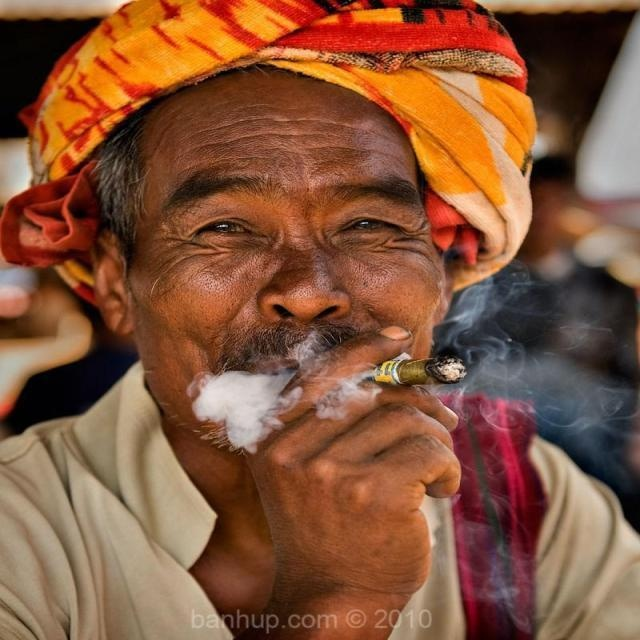

IMG_3807-1-_jpeg_jpg.rf.104705c3cbafb01e645d08323b8d91d5.jpg


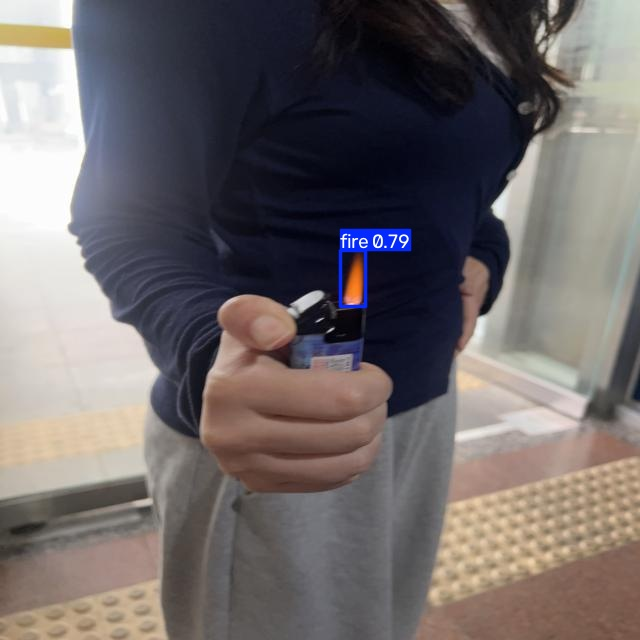

Img_1829_jpg.rf.6559427db14126b2701a7f20622085bf.jpg


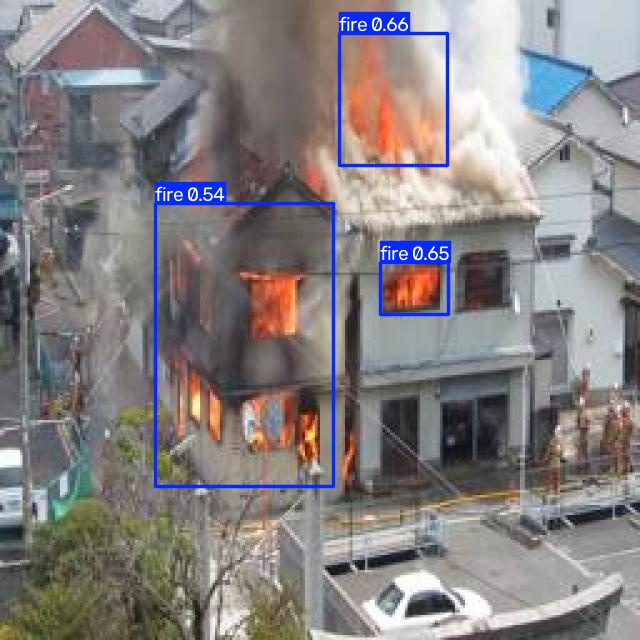

In [11]:
from pathlib import Path
from IPython.display import display, Image
from ultralytics import YOLO
import random

BEST_MODEL_PATH = (
    PROJECT_ROOT
    / "runs/fire_smoke/yolo26n_fire_smoke_v1/weights/best.pt"
)

TEST_IMAGES_DIR = DATASET_DIR / "test/images"
PREDICTION_DIR = PROJECT_ROOT / "runs/fire_smoke/practical_image_test"

assert BEST_MODEL_PATH.is_file(), "Best checkpoint not found."
assert TEST_IMAGES_DIR.is_dir(), "Test images folder not found."

best_model = YOLO(str(BEST_MODEL_PATH))

# Select up to three test images without modifying them.
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
test_images = sorted(
    p for p in TEST_IMAGES_DIR.iterdir()
    if p.suffix.lower() in image_extensions
)

random.seed(42)
selected_images = random.sample(test_images, min(3, len(test_images)))

print("Selected test images:", len(selected_images))

# Save annotated predictions in a separate output folder.
best_model.predict(
    source=[str(p) for p in selected_images],
    imgsz=640,
    conf=0.25,
    device=0,
    save=True,
    project=str(PROJECT_ROOT / "runs/fire_smoke"),
    name="practical_image_test",
    exist_ok=True,
    verbose=True,
)

PREDICTION_DIR = PROJECT_ROOT / "runs/fire_smoke/practical_image_test"
saved_images = sorted(PREDICTION_DIR.glob("*"))

print("\nAnnotated output folder:", PREDICTION_DIR)
for path in saved_images:
    if path.suffix.lower() in image_extensions:
        print(path.name)
        display(Image(filename=str(path)))

In [ ]:
## Analyze Detection Confidence Thresholds

I have evaluated the trained fire/smoke detector on the held-out test dataset. Before changing the model or starting another training run, I will investigate how detection confidence thresholds affect precision and recall.

This experiment will help determine whether a different threshold can reduce false alarms without causing too many missed fire or smoke detections. I will keep the trained checkpoint and original test data unchanged.

In [ ]:
###Compare Confidence Thresholds

I will evaluate the existing best checkpoint on the validation split using several confidence thresholds. A lower threshold may recover more fire or smoke detections but can also increase false alarms. A higher threshold may reduce false alarms while missing more objects.

I will compare precision, recall, and mAP across thresholds without modifying the trained model or dataset. The validation results will guide further experiments; the held-out test results will remain our final independent benchmark.

In [12]:
import pandas as pd

thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]
threshold_results = []

for conf_threshold in thresholds:
    metrics = best_model.val(
        data=str(DATA_YAML),
        split="val",
        imgsz=640,
        batch=16,
        device=0,
        conf=conf_threshold,
        plots=False,
        verbose=False,
    )

    threshold_results.append({
        "confidence_threshold": conf_threshold,
        "precision": round(float(metrics.box.mp), 4),
        "recall": round(float(metrics.box.mr), 4),
        "mAP50": round(float(metrics.box.map50), 4),
        "mAP50_95": round(float(metrics.box.map), 4),
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df)

Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.7±0.1 ms, read: 0.1±0.0 MB/s, size: 33.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/FireWatch-AI/datasets/candidates/fire_smoke_v2_bbox_candidate/valid/labels.cache... 684 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 684/684 168.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 43/43 3.3it/s 13.0s
                   all        684       1038      0.921      0.859      0.895      0.637
Speed: 1.4ms preprocess, 4.6ms inference, 0.0ms loss, 1.9ms postprocess per image
Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary

,confidence_threshold,precision,recall,mAP50,mAP50_95
0,0.10,0.9214,0.8590,0.8947,0.6371
1,0.15,0.9214,0.8590,0.8867,0.6328
2,0.20,0.9214,0.8590,0.8794,0.6293
3,0.25,0.9214,0.8590,0.8709,0.6274
4,0.30,0.9214,0.8590,0.8668,0.6242
5,0.40,0.9213,0.8569,0.8497,0.6161
6,0.50,0.9455,0.8366,0.8268,0.6077


In [ ]:
## Inspect Difficult Fire and Smoke Examples

I have compared several confidence thresholds on the validation split. The results suggest that threshold changes alone are not enough to establish a reliable deployment setting.

I will now inspect predictions on validation images to identify difficult examples, missed objects, and potentially incorrect detections. This will help determine whether the next improvement should focus on data quality, model training, or inference settings.

Validation images selected: 6
Results saved to /content/drive/MyDrive/FireWatch-AI/runs/fire_smoke/error_review

Prediction: 000245_jpeg_jpg.rf.8e71dd951eb21b190a39d1bfd31d5a83.jpg


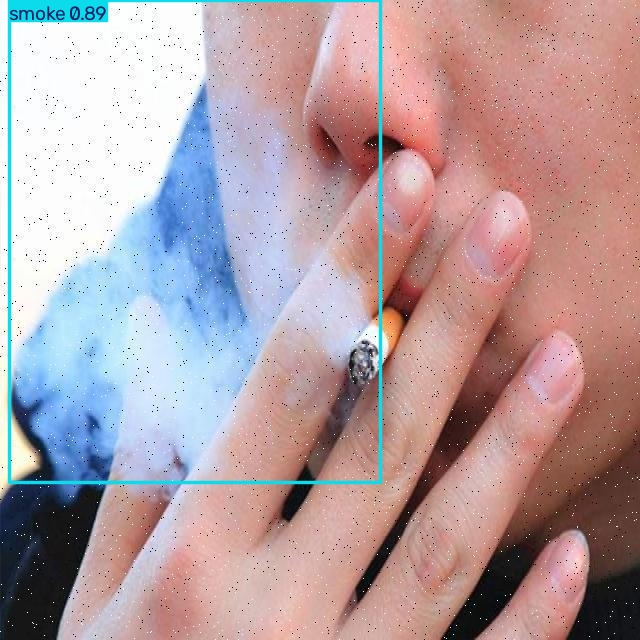


Prediction: IMG_5385-1-_jpeg_jpg.rf.2b48615927b10a1686f78e3402d9b4e6.jpg


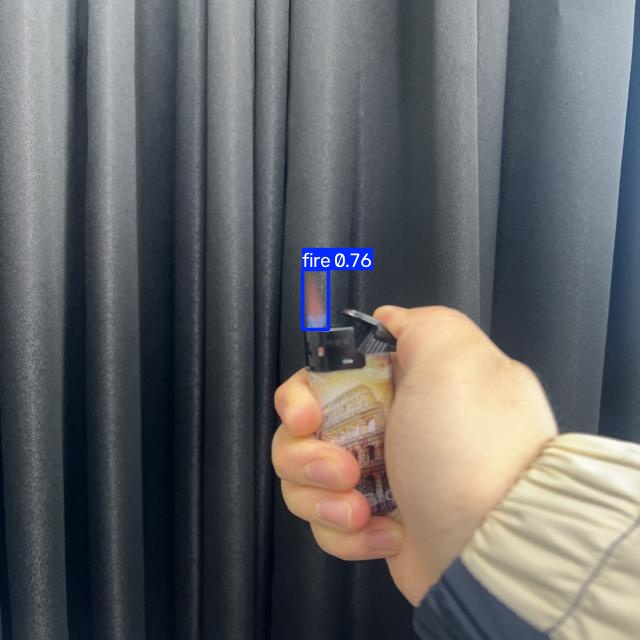


Prediction: Img_1392_jpg.rf.ea33cc6cff8dc1aeda4412ec27d2e68c.jpg


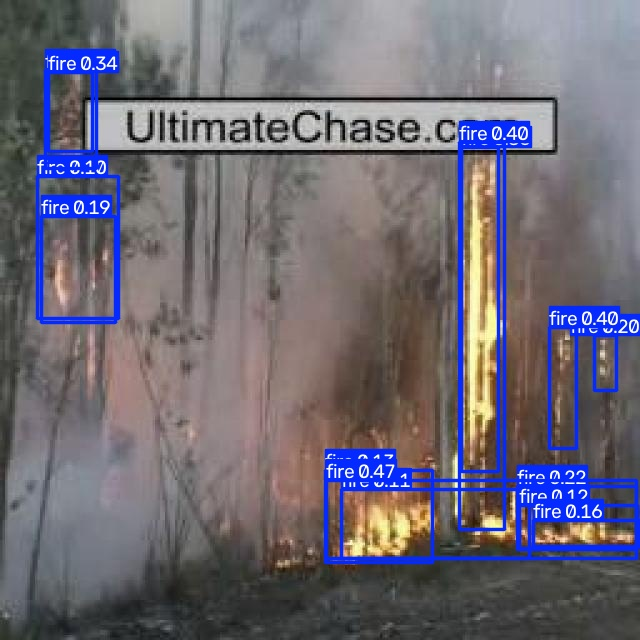


Prediction: Img_1691_jpg.rf.e40bcd8562555da906243ff5645fb238.jpg


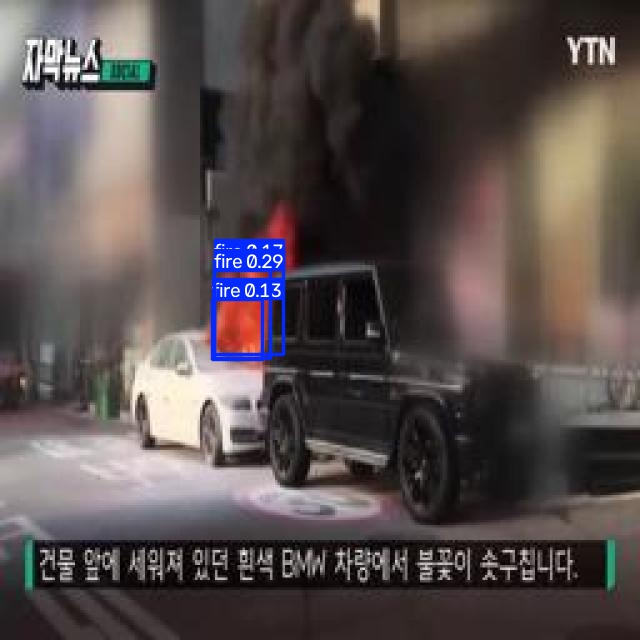


Prediction: Img_1718_jpg.rf.2343e07f10eb3ebabb58224202f6c1a4.jpg


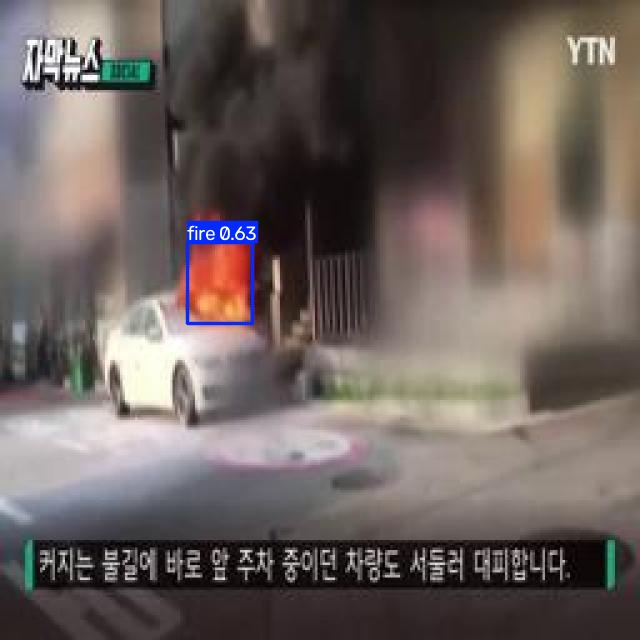


Prediction: youtube-0_jpg.rf.ebaf9ea1444747dd245a1805867a30b9.jpg


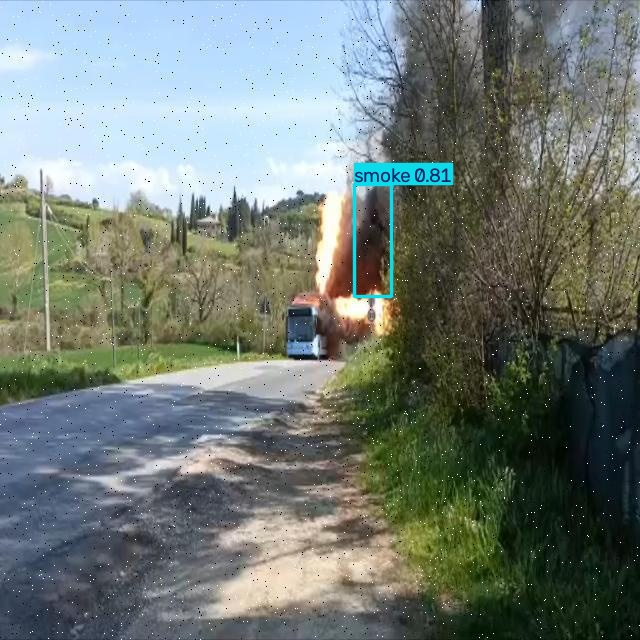

In [13]:
from pathlib import Path
import random
from ultralytics import YOLO
from IPython.display import display, Image

VAL_IMAGES_DIR = DATASET_DIR / "valid/images"
ERROR_REVIEW_DIR = PROJECT_ROOT / "runs/fire_smoke/error_review"

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
val_images = sorted(
    p for p in VAL_IMAGES_DIR.iterdir()
    if p.suffix.lower() in image_extensions
)

random.seed(42)
selected_images = random.sample(val_images, min(6, len(val_images)))

print("Validation images selected:", len(selected_images))

best_model.predict(
    source=[str(p) for p in selected_images],
    imgsz=640,
    conf=0.10,
    device=0,
    save=True,
    project=str(PROJECT_ROOT / "runs/fire_smoke"),
    name="error_review",
    exist_ok=True,
    verbose=False,
)

for image_path in sorted(ERROR_REVIEW_DIR.iterdir()):
    if image_path.suffix.lower() in image_extensions:
        print("\nPrediction:", image_path.name)
        display(Image(filename=str(image_path)))

In [ ]:
## Review Validation Predictions Against Ground Truth

I have visually inspected sample predictions and identified cases that need closer review. I will now compare the model's predictions with the original validation annotations on a small set of images.

This will help identify missed objects, incorrect classes, and poorly localized boxes. I will use the validation split for error analysis and keep the original annotations unchanged. I will not start another training run until the findings justify it.

In [14]:
from pathlib import Path
import random
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

# Select six validation images using a reproducible seed.
VAL_IMAGES_DIR = DATASET_DIR / "valid/images"
VAL_LABELS_DIR = DATASET_DIR / "valid/labels"

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
val_images = sorted(
    p for p in VAL_IMAGES_DIR.iterdir()
    if p.suffix.lower() in image_extensions
)

random.seed(42)
review_images = random.sample(val_images, min(6, len(val_images)))

# Predict with the existing checkpoint, without saving or changing images.
review_results = best_model.predict(
    source=[str(p) for p in review_images],
    imgsz=640,
    conf=0.10,
    device=0,
    save=False,
    verbose=False,
)

class_names = best_model.names

for image_path, result in zip(review_images, review_results):
    print("\nImage:", image_path.name)

    # Show the original image with ground-truth annotations.
    original = Image.open(image_path).convert("RGB")
    label_path = VAL_LABELS_DIR / f"{image_path.stem}.txt"

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    axes[0].imshow(original)
    axes[0].set_title("Ground truth")
    axes[0].axis("off")

    # YOLO labels are normalized: class_id, center_x, center_y, width, height.
    if label_path.is_file():
        width, height = original.size

        for line in label_path.read_text().splitlines():
            parts = line.split()
            if len(parts) != 5:
                continue

            class_id, cx, cy, bw, bh = map(float, parts)
            x1 = (cx - bw / 2) * width
            y1 = (cy - bh / 2) * height

            rect = plt.Rectangle(
                (x1, y1),
                bw * width,
                bh * height,
                fill=False,
                edgecolor="lime",
                linewidth=2,
            )
            axes[0].add_patch(rect)
            axes[0].text(
                x1, max(0, y1 - 4),
                class_names[int(class_id)],
                color="black",
                backgroundcolor="lime",
                fontsize=9,
            )

    # Show predictions on the second panel.
    axes[1].imshow(result.plot()[..., ::-1])
    axes[1].set_title("Model predictions (conf = 0.10)")
    axes[1].axis("off")

    plt.tight_layout()
    display(fig)
    plt.close(fig)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
###Compare Inference Settings

I observed overlapping fire predictions in some validation examples. Before retraining, I will compare the existing model's predictions under different confidence and IoU settings.

This experiment changes only inference settings. It does not modify model weights, training data, or annotations. I will use the same validation images for a fair visual comparison.

Image selected: Img_1392_jpg.rf.2a47e09924a53391b4aa87638efc3ea4.jpg


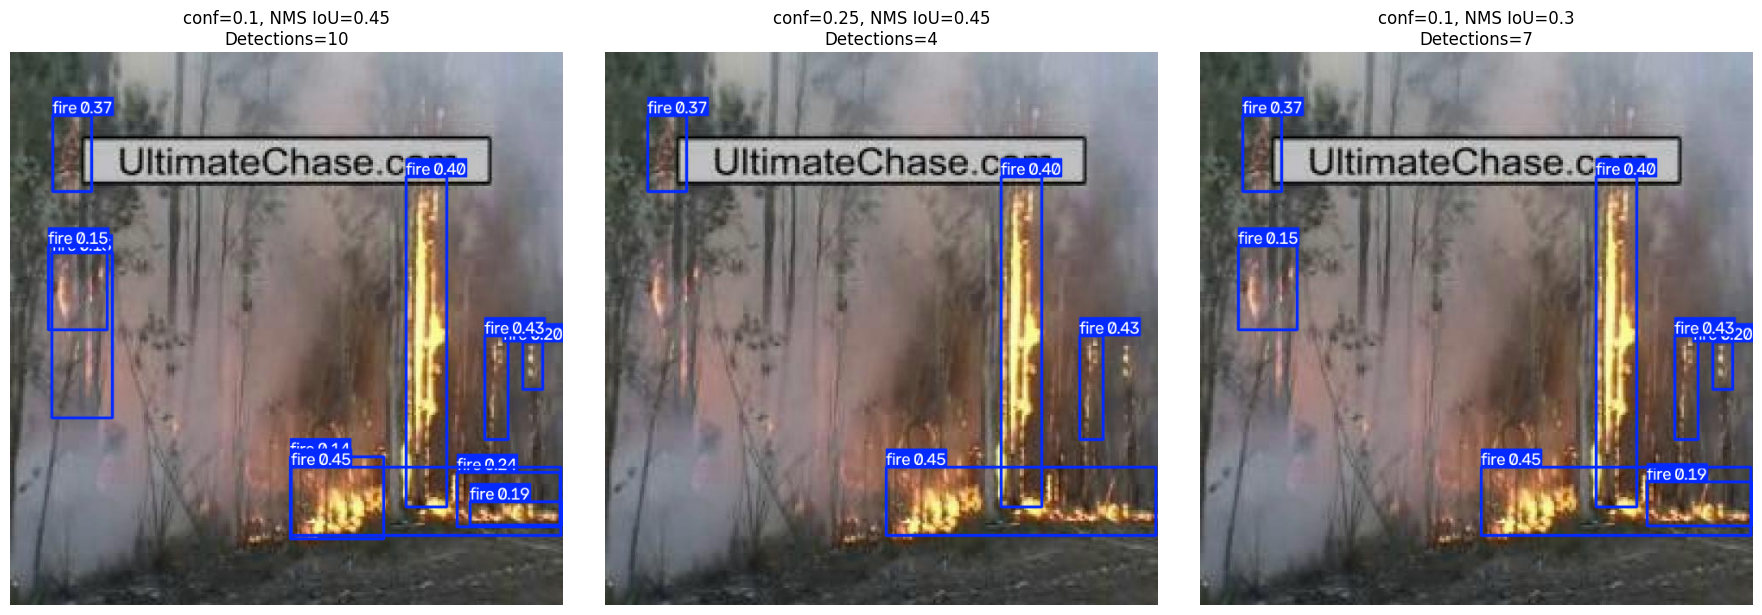

In [15]:
from pathlib import Path
from IPython.display import display, Image
import matplotlib.pyplot as plt

VAL_IMAGES_DIR = DATASET_DIR / "valid/images"

matches = list(VAL_IMAGES_DIR.glob("Img_1392*"))

if not matches:
    matches = list(VAL_IMAGES_DIR.glob("*1392*"))

if not matches:
    raise FileNotFoundError(
        "Could not find the reviewed fire image. "
        "Please provide its exact filename from the earlier output."
    )

review_image = matches[0]
print("Image selected:", review_image.name)

settings = [
    {"conf": 0.10, "iou": 0.45},
    {"conf": 0.25, "iou": 0.45},
    {"conf": 0.10, "iou": 0.30},
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, setting in zip(axes, settings):
    result = best_model.predict(
        source=str(review_image),
        imgsz=640,
        conf=setting["conf"],
        iou=setting["iou"],
        device=0,
        save=False,
        verbose=False,
    )[0]

    ax.imshow(result.plot()[..., ::-1])
    ax.set_title(
        f"conf={setting['conf']}, NMS IoU={setting['iou']}\n"
        f"Detections={len(result.boxes)}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
##Fine-Tune the Fire/Smoke Detector

I will start a separate fine-tuning experiment from the existing best checkpoint. I will use a lower learning rate and a limited number of additional epochs to make smaller weight updates.

The original trained checkpoint, dataset, and previous results will remain unchanged. I will compare the new model against the original using the validation split before deciding which checkpoint to keep.

In [16]:
from pathlib import Path
from ultralytics import YOLO

# Start from the best existing checkpoint.
BEST_MODEL_PATH = (
    PROJECT_ROOT
    / "runs/fire_smoke/yolo26n_fire_smoke_v1/weights/best.pt"
)

assert BEST_MODEL_PATH.is_file(), "Original best checkpoint not found."

fine_tune_model = YOLO(str(BEST_MODEL_PATH))

FINE_TUNE_CONFIG = {
    "data": str(DATA_YAML),
    "epochs": 15,
    "imgsz": 640,
    "batch": 16,
    "device": 0,
    "seed": 42,
    "deterministic": True,
    "workers": 2,
    "lr0": 0.001,
    "patience": 5,
    "close_mosaic": 3,
    "project": str(PROJECT_ROOT / "runs/fire_smoke"),
    "name": "yolo26n_fire_smoke_finetune_v1",
    "exist_ok": False,
    "plots": True,
    "save": True,
    "val": True,
}

print("Starting separate fine-tuning experiment.")
print("Original checkpoint:", BEST_MODEL_PATH)
print("Configuration:", FINE_TUNE_CONFIG)

fine_tune_results = fine_tune_model.train(**FINE_TUNE_CONFIG)

print("\nFine-tuning run finished.")
print(
    "New best checkpoint:",
    PROJECT_ROOT
    / "runs/fire_smoke/yolo26n_fire_smoke_finetune_v1/weights/best.pt"
)

Starting separate fine-tuning experiment.
Original checkpoint: /content/drive/MyDrive/FireWatch-AI/runs/fire_smoke/yolo26n_fire_smoke_v1/weights/best.pt
Configuration: {'data': '/content/drive/MyDrive/FireWatch-AI/datasets/candidates/fire_smoke_v2_bbox_candidate/data.yaml', 'epochs': 15, 'imgsz': 640, 'batch': 16, 'device': 0, 'seed': 42, 'deterministic': True, 'workers': 2, 'lr0': 0.001, 'patience': 5, 'close_mosaic': 3, 'project': '/content/drive/MyDrive/FireWatch-AI/runs/fire_smoke', 'name': 'yolo26n_fire_smoke_finetune_v1', 'exist_ok': False, 'plots': True, 'save': True, 'val': True}
Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=3, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=

In [ ]:
## Compare Original and Fine-Tuned Models

I will record the validation metrics from both models and select the checkpoint based on overall detection quality, not just one metric. The original model will remain unchanged, and I will not replace it unless the comparison supports that decision.

In [17]:
import json
from pathlib import Path

REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

comparison = {
    "original_model": {
        "checkpoint": str(
            PROJECT_ROOT
            / "runs/fire_smoke/yolo26n_fire_smoke_v1/weights/best.pt"
        ),
        "precision": 0.9214,
        "recall": 0.8590,
        "mAP50": 0.8947,
        "mAP50_95": 0.6371,
    },
    "fine_tuned_model": {
        "checkpoint": str(
            PROJECT_ROOT
            / "runs/fire_smoke/yolo26n_fire_smoke_finetune_v1/weights/best.pt"
        ),
        "precision": 0.922,
        "recall": 0.824,
        "mAP50": 0.896,
        "mAP50_95": 0.603,
    },
    "decision": (
        "Keep original as primary model pending further error analysis. "
        "Fine-tuned model does not show a clear overall improvement."
    ),
}

report_path = REPORTS_DIR / "fire_smoke_finetuning_comparison.json"
report_path.write_text(json.dumps(comparison, indent=2), encoding="utf-8")

print("Comparison saved:", report_path)
print("Original checkpoint preserved:", Path(comparison["original_model"]["checkpoint"]).is_file())
print("Fine-tuned checkpoint preserved:", Path(comparison["fine_tuned_model"]["checkpoint"]).is_file())
print("Decision:", comparison["decision"])

Comparison saved: /content/drive/MyDrive/FireWatch-AI/reports/fire_smoke_finetuning_comparison.json
Original checkpoint preserved: True
Fine-tuned checkpoint preserved: True
Decision: Keep original as primary model pending further error analysis. Fine-tuned model does not show a clear overall improvement.


In [ ]:
## Final Summary: Fire and Smoke Detection

### Completed
- Trained YOLO26n on the prepared fire/smoke dataset for 50 epochs.
- Evaluated the original model on the held-out test set.
- Saved training plots and confusion matrices in `docs/images/`.
- Saved test metrics in `reports/fire_smoke_test_metrics.json`.
- Inspected practical predictions and compared ground-truth annotations with model outputs.
- Tested multiple inference confidence thresholds and NMS IoU settings.
- Ran a separate fine-tuning experiment with early stopping.
- Saved the original versus fine-tuned model comparison in `reports/fire_smoke_finetuning_comparison.json`.

### Current Model Decision
The original checkpoint remains the primary model because fine-tuning did not demonstrate a clear overall improvement.

### Important Results
Original held-out test metrics:
- Precision: 90.71%
- Recall: 82.73%
- mAP@50: 87.07%
- mAP@50–95: 59.71%

Fine-tuning achieved validation mAP@50 of approximately 89.6%, but recall and mAP@50–95 were lower than the original model's validation results.

